# 06 · Topological data analysis I: lower-star filtration

**Idea.** Persistent homology describes the *shape* of a signal across
scales. For an image $f$ we grow the sublevel sets
$\{x : f(x) \le t\}$ as $t$ increases from 0 to 1 and record when connected
components (**H0**) and loops (**H1**) appear (*birth*) and disappear
(*death*). Each feature becomes a point (birth, death) of a **persistence
diagram**. Features far from the diagonal are long-lived, robust structures;
points near it are noise.

On the pixel grid this is the **lower-star filtration** of a cubical
complex (`gudhi.CubicalComplex`). Pixels below an intensity threshold are
treated as background and moved to 1.0, so they enter last, all at once,
instead of dominating the filtration.

**Vectorisations.** Diagrams are not vectors, so for classification each
diagram is summarised by:

- the **persistence landscape** (5 layers × 400 samples);
- the **Betti curve** β(t): number of features alive at $t$;
- the **lifetime curve** L(t): total persistence of the features alive at $t$;
- **barcode statistics**: count, total, maximum and std of the persistences.

**Data.** A balanced AD/CN subset: 106 AD and 106 randomly chosen CN
subjects, split at random into 96 + 96 for training and 10 + 10 for test.
The same subjects are used in every view.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adni_tau.paths import save_figure, save_table
from adni_tau.tda import config
from adni_tau.tda.classification import (
    coefficient_importance_by_view,
    cross_validate_logistic_multiview,
    descriptor_importance,
    fit_eval_logistic_multiview,
    run_nearest_template_classification,
    summarize_results,
    top_logistic_coefficients,
)
from adni_tau.tda.data import load_all_views
from adni_tau.tda.pca_analysis import explained_variance_table, fit_eval_pca_logistic, fit_pca_multiview, pca_logistic_with_pvalues, top_loadings_for_component
from adni_tau.tda.plotting import (
    plot_class_templates,
    plot_curve_bands_by_view,
    plot_diagram_and_barcode,
    plot_landscape_layers,
    plot_pca_scatter,
    plot_results_bars,
)
from adni_tau.tda.templates import compute_class_templates_for_view, compute_template_tda
from adni_tau.tda.topology import compute_tda_for_images

plt.rcParams["figure.dpi"] = 90
VIEWS = ["axial", "coronal", "sagittal"]
THRESHOLD_BY_VIEW = {"axial": 0.25, "coronal": 0.25, "sagittal": 0.25}
LOGIT_C = 0.1

data_by_view = load_all_views(VIEWS)
y_train, y_test = data_by_view[VIEWS[0]]["y_train"], data_by_view[VIEWS[0]]["y_test"]

   axial: train (192, 182, 218), test (20, 182, 218)


 coronal: train (192, 182, 182), test (20, 182, 182)


sagittal: train (192, 182, 218), test (20, 182, 218)


## 1. Class templates

Average AD and CN image per view (training set, background set to 0). The
difference map shows where tau uptake is higher in AD.

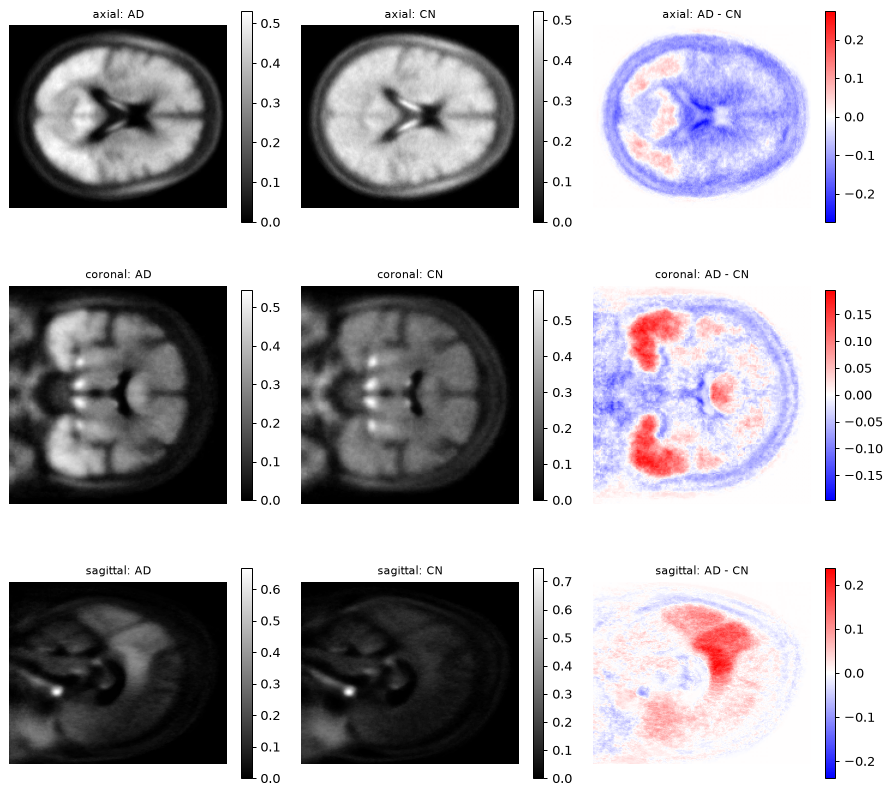

In [2]:
templates_by_view = {
    v: compute_class_templates_for_view(data_by_view[v]["train_imgs"], y_train, lower_star_threshold=THRESHOLD_BY_VIEW[v], point_cloud_threshold=THRESHOLD_BY_VIEW[v])
    for v in VIEWS
}
fig = plot_class_templates(templates_by_view, VIEWS)
save_figure(fig, "06_class_templates")

## 2. Persistent homology of every image

In [3]:
tda_by_view = {
    v: {
        part: compute_tda_for_images(data_by_view[v][f"{part}_imgs"], filtration_type="lower_star", threshold=THRESHOLD_BY_VIEW[v])
        for part in ("train", "test")
    }
    for v in VIEWS
}
for v in VIEWS:
    n_h0 = [d.shape[0] for d in tda_by_view[v]["train"]["diag_h0"]]
    n_h1 = [d.shape[0] for d in tda_by_view[v]["train"]["diag_h1"]]
    print(f"{v:>8}: median features per image H0 = {int(np.median(n_h0))}, H1 = {int(np.median(n_h1))}")

   axial: median features per image H0 = 2531, H1 = 997
 coronal: median features per image H0 = 1166, H1 = 860
sagittal: median features per image H0 = 1499, H1 = 23


### One subject, step by step

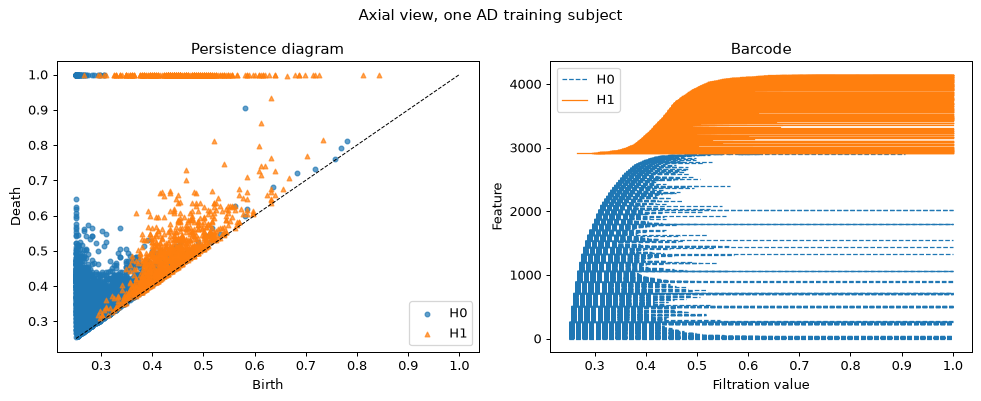

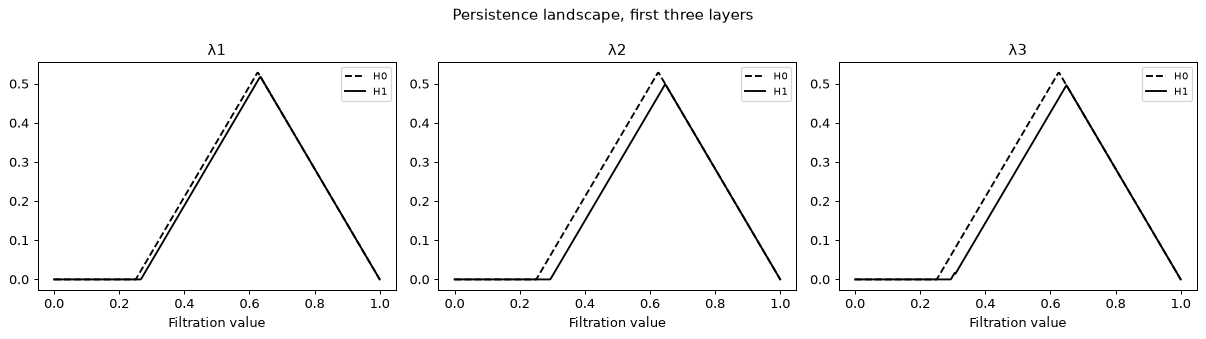

In [4]:
tda0 = tda_by_view["axial"]["train"]
fig = plot_diagram_and_barcode(tda0["diag_h0"][0], tda0["diag_h1"][0], title="Axial view, one AD training subject")
save_figure(fig, "06_example_diagram_barcode")
fig = plot_landscape_layers(tda0["land_h0"][0], tda0["land_h1"][0], layers=(0, 1, 2), title="Persistence landscape, first three layers")
save_figure(fig, "06_example_landscape")

## 3. Do AD and CN differ topologically?

Median Betti and lifetime curves per class, with interquartile bands
(training set). Dashed = H0 (components), solid = H1 (loops).

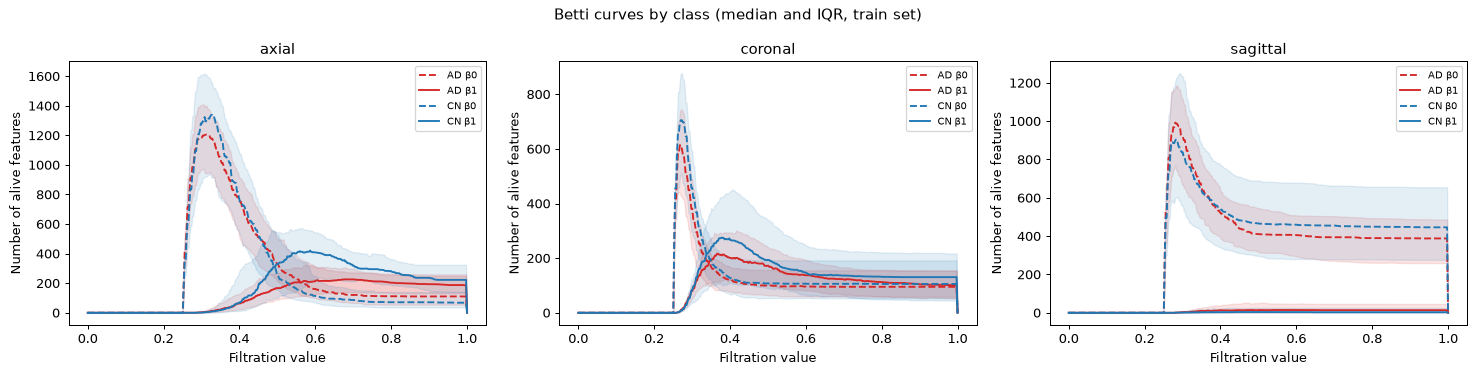

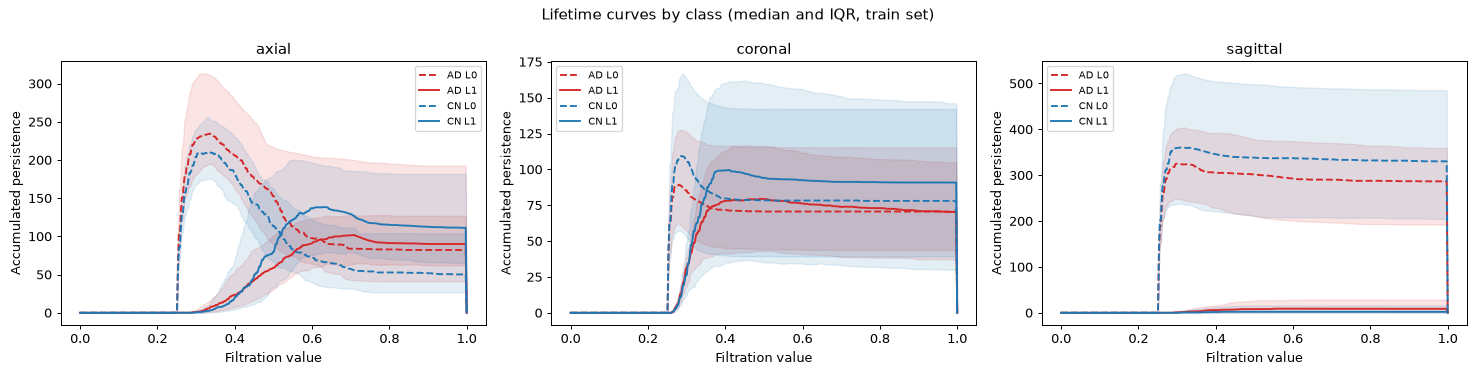

In [5]:
fig = plot_curve_bands_by_view(tda_by_view, y_train, VIEWS, kind="betti")
save_figure(fig, "06_betti_curves_by_class")
fig = plot_curve_bands_by_view(tda_by_view, y_train, VIEWS, kind="lifetime")
save_figure(fig, "06_lifetime_curves_by_class")

**What the curves show.** In the axial and coronal views, CN subjects have
**more H1 loops at intermediate filtration values** (about 0.4–0.7) than AD
subjects. A plausible reading is that in AD the high-uptake regions are
larger and more confluent, so fewer separate cycles form at those intensity
levels (a hypothesis, not tested here). The interquartile bands
overlap heavily, though: the difference is real at the group level but weak
for any single subject.

## 4. Classification

### 4.1 Nearest template

Each test subject is assigned to the class whose template diagram is closer
(bottleneck or 1-Wasserstein distance, summed over H0, H1 and views). There
is no training beyond building the templates.

In [6]:
template_tda_by_view = {v: compute_template_tda(templates_by_view[v], filtration_type="lower_star") for v in VIEWS}
results = []
for metric in ("bottleneck", "wasserstein"):
    _, m = run_nearest_template_classification(tda_by_view, template_tda_by_view, y_test, VIEWS, metric=metric, verbose=False)
    results.append(m)

### 4.2 Multi-view logistic regression

All descriptors of all views are concatenated (≈14,000 features for 192
training subjects), standardised and fed to an L2-regularised logistic
regression ($C = 0.1$). With only 20 test subjects, a test accuracy moves in
steps of 5 points, so we also report **repeated 5-fold cross-validation**
on all 212 subjects (10 repeats).

In [7]:
logit = fit_eval_logistic_multiview(tda_by_view, y_train, y_test, VIEWS, C=LOGIT_C, verbose=False)
results += [logit["metrics_train"], logit["metrics_test"]]
cv_scores = cross_validate_logistic_multiview(tda_by_view, y_train, y_test, VIEWS, C=LOGIT_C)
save_table(pd.DataFrame([{"pipeline": "lower-star", **cv_scores}]), "06_lower_star_cv")
print("Repeated 5-fold CV:", {k: round(v, 3) for k, v in cv_scores.items()})

Repeated 5-fold CV: {'cv_accuracy_mean': 0.667, 'cv_accuracy_std': 0.07, 'cv_balanced_accuracy_mean': 0.668, 'cv_balanced_accuracy_std': 0.07}


### 4.3 PCA on the topological features

A PCA keeping 95% of the variance, then logistic regression on the
components. With few components, an **unregularised** logistic regression is
identifiable, so Wald p-values can be computed for each component.

PCA: 20 components explain 95.3% of the variance (16824 features, 192 training subjects).


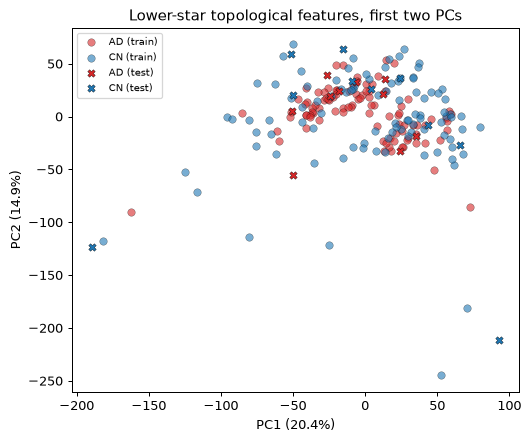

In [8]:
pca_result = fit_pca_multiview(tda_by_view, VIEWS, n_components=0.95)
pca_logit = fit_eval_pca_logistic(pca_result, y_train, y_test, verbose=False)
results += [pca_logit["metrics_train"], pca_logit["metrics_test"]]
fig = plot_pca_scatter(pca_result, y_train, y_test, title="Lower-star topological features, first two PCs")
save_figure(fig, "06_pca_scatter")

In [9]:
try:
    pvals = pca_logistic_with_pvalues(pca_result, y_train, max_components=10)
    display(pvals.round(4))
    best_pc = pvals.loc[pvals["component"] != "const", "component"].iloc[0]
    print(f"Original features with the largest loadings on {best_pc}:")
    display(top_loadings_for_component(pca_result, int(best_pc[2:]) - 1, top_n=10))
except RuntimeError as exc:
    print(exc)

,component,coef,std_err,z,p_value
0,PC7,-0.1048,0.0253,-4.1406,0.0000
1,PC6,0.0510,0.0138,3.7073,0.0002
2,PC2,-0.0207,0.0080,-2.5949,0.0095
3,PC3,0.0090,0.0061,1.4689,0.1419
4,PC8,0.0136,0.0111,1.2227,0.2214
5,PC9,-0.0236,0.0230,-1.0256,0.3051
6,const,0.1767,0.1992,0.8872,0.3750
7,PC10,0.0054,0.0149,0.3649,0.7152
8,PC4,0.0021,0.0075,0.2816,0.7783
9,PC5,-0.0029,0.0115,-0.2558,0.7981


Original features with the largest loadings on PC7:


,feature,loading,view,abs_loading
0,axial_landscape_h1_layer1_pt318,0.028622,axial,0.028622
1,axial_landscape_h1_layer2_pt318,0.028617,axial,0.028617
2,axial_landscape_h1_layer2_pt317,0.028614,axial,0.028614
3,axial_landscape_h1_layer1_pt317,0.028610,axial,0.028610
4,axial_landscape_h1_layer1_pt319,0.028578,axial,0.028578
5,axial_landscape_h1_layer2_pt316,0.028555,axial,0.028555
6,axial_landscape_h1_layer1_pt316,0.028555,axial,0.028555
7,axial_landscape_h1_layer2_pt319,0.028551,axial,0.028551
8,axial_landscape_h1_layer1_pt315,0.028499,axial,0.028499
9,axial_landscape_h1_layer2_pt315,0.028489,axial,0.028489


## 5. Summary

In [10]:
summary = summarize_results(results)
summary["model"] = summary["model"].str.replace("Multi-view logistic regression", "Logistic regression (all features)")
summary = pd.concat(
    [summary, pd.DataFrame([{"model": "Logistic regression (all features)", "split": "5-fold CV ×10", "accuracy": cv_scores["cv_accuracy_mean"], "balanced_accuracy": cv_scores["cv_balanced_accuracy_mean"]}])],
    ignore_index=True,
)
save_table(summary, "06_lower_star_results")
summary.round(3)

,model,split,accuracy,balanced_accuracy
0,Nearest template (bottleneck),test,0.500,0.500
1,Nearest template (wasserstein),test,0.500,0.500
2,Logistic regression (all features),train,0.979,0.979
3,Logistic regression (all features),test,0.850,0.850
4,PCA + logistic regression,train,0.771,0.771
5,PCA + logistic regression,test,0.750,0.750
6,Logistic regression (all features),5-fold CV ×10,0.667,0.668


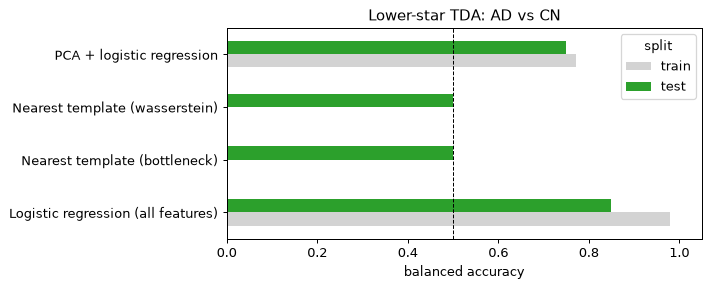

In [11]:
fig = plot_results_bars(summary[summary["split"].isin(["train", "test"])], title="Lower-star TDA: AD vs CN")
save_figure(fig, "06_lower_star_results")

**Reading the results.**

- **Nearest template is at chance.** A single average diagram per class
  washes out the subject-level variability that matters.
- **The fixed test set is optimistic.** The all-features logistic regression
  reaches 0.85 on the 20 test subjects, but repeated cross-validation over
  all 212 subjects gives **0.67 ± 0.07**. With 20 test subjects one error is
  5 points, so the CV estimate is the number to trust.
- **Overfitting.** Train accuracy is ≈ 0.98 with ~17,000 features for 192
  subjects, even with strong L2 regularisation. The PCA model is less
  overfit (train 0.77, test 0.75).
- **H1 landscapes carry most of the weight** in all views (table below),
  consistent with the loop-count differences in the Betti curves.

### Which views and descriptors drive the logistic model?

In [12]:
display(coefficient_importance_by_view(logit))
imp = descriptor_importance(logit, VIEWS)
imp_per_view = imp.pivot_table(index=["descriptor", "homology"], columns="view", values="abs_coef")
display(imp_per_view.round(3))
display(top_logistic_coefficients(logit, VIEWS, top_n=10))

,view,sum_abs_coef,n_nonzero,n_features
0,axial,33.625352,4114,5608
1,coronal,30.218450,4172,5608
2,sagittal,27.283495,4133,5608


view                  axial  coronal  sagittal
descriptor homology                           
barcode    h0         0.124    0.129     0.077
           h1         0.152    0.173     0.105
betti      h0         2.977    1.852     3.197
           h1         8.657    5.662     3.582
landscape  h0         0.000    3.675     0.199
           h1        16.493   15.754    16.393
lifetime   h0         1.014    0.369     2.014
           h1         4.209    2.605     1.717

,feature,view,coef,abs_coef,favours
0,coronal_landscape_h1_layer2_pt104,coronal,0.203466,0.203466,CN
1,coronal_landscape_h1_layer0_pt103,coronal,-0.167497,0.167497,AD
2,coronal_landscape_h1_layer0_pt105,coronal,0.154234,0.154234,CN
3,coronal_barcode_h1_std_persistence,coronal,-0.152917,0.152917,AD
4,axial_lifetime_h1_pt107,axial,-0.148861,0.148861,AD
5,coronal_betti_h1_pt104,coronal,0.148029,0.148029,CN
6,coronal_landscape_h1_layer2_pt106,coronal,0.147258,0.147258,CN
7,axial_landscape_h1_layer3_pt111,axial,0.145213,0.145213,CN
8,axial_betti_h1_pt107,axial,-0.144767,0.144767,AD
9,coronal_landscape_h1_layer1_pt104,coronal,0.142453,0.142453,CN
